# Predicting Myopia from Eye Measurements and Lifestyle Data
**Machine Learning — Final Project (2026/27)**

**Team:** Patricia Urdiroz, Luis Martín

**What this notebook does.** For third-year medical students we predict four labels:
* whether they have myopia (`M`);
* whether they have severe myopia (`MM`);
* the group C / M / MM (`Combo`);
* the group C / M1 / M2 / MM (`DCombo`).

We explore the data, build a few new variables from what the exploration shows, select the
useful variables with Lasso, compare a small set of models for each task and check the
chosen ones on data they have never seen.

**Contents:** 0. Setup · 1. The problem and wrong labels · 2. Hold-out set · 3. Data preparation ·
4. Exploratory analysis · 5. New variables and variable selection · 6. Models ·
7. Final check on the hold-out set · 8. Predictions for the test set · 9. Conclusions

## 0. Setup

Anyone with this notebook and the three data files (`X_train.csv`, `Y_train.csv`,
`X_test.csv`) can reproduce every result:
* the data folder is set in `DATA_DIR`;
* every random step uses the same seed;
* the libraries are standard (see the versions printed below and `requirements.txt`).

On macOS, XGBoost needs the OpenMP runtime: run `brew install libomp` once.

In [1]:
# Libraries, data folder and random seed
import os
import warnings
from pathlib import Path

os.environ["PYTHONWARNINGS"] = "ignore"  # keep the output clean, also in parallel workers
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display

DATA_DIR = Path("data")          # folder with X_train.csv, Y_train.csv and X_test.csv
SEED = 42
TASKS = ["M", "MM", "Combo", "DCombo"]
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1


In [2]:
# Chart style: no myopia -> myopia -> severe myopia use one blue scale (light to dark).
# M1 and M2 are two types of myopia, not two degrees, so they get two different hues.
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
DCOMBO_ORDER, COMBO_ORDER = ["C", "M1", "M2", "MM"], ["C", "M", "MM"]
DCOMBO_COLORS = dict(zip(DCOMBO_ORDER, ["#86b6ef", BLUE, GREEN, "#0d366b"]))
COMBO_COLORS = dict(zip(COMBO_ORDER, ["#86b6ef", "#2a78d6", "#0d366b"]))
YESNO_COLORS = {"NO": "#86b6ef", "SI": "#1c5cab"}
ORDERS = {"M": ["NO", "SI"], "MM": ["NO", "SI"], "Combo": COMBO_ORDER, "DCombo": DCOMBO_ORDER}
COLORS = {"M": YESNO_COLORS, "MM": YESNO_COLORS, "Combo": COMBO_COLORS, "DCombo": DCOMBO_COLORS}

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "legend.frameon": False, "figure.dpi": 110})

## 1. The problem

We have **132 labelled students** (`X_train.csv` + `Y_train.csv`) and **24 unlabelled
students** (`X_test.csv`) whose labels we must predict. For each student the data contain:
* basic information (age, sex);
* weekly hours of outdoor and indoor activities;
* family history of myopia;
* sun habits;
* measurements of both eyes: length, curvature of the front surface, and a marker of sun
  damage on the white of the eye.

| Task | Question | Classes |
|---|---|---|
| `M` | Is the student myopic? | `SI` / `NO` |
| `MM` | Is the student severely myopic? | `SI` / `NO` |
| `Combo` | No myopia, myopia or severe myopia? | `C` / `M` / `MM` |
| `DCombo` | Same as `Combo`, with myopia split into two types | `C` / `M1` / `M2` / `MM` |

The models are compared mainly by **accuracy** (share of correctly predicted students),
because that is the score that decides the competition. Precision, recall, F1-score,
ROC AUC and MSE are also reported, because some classes are rare and accuracy alone can
hide problems.

In [3]:
# Read the labelled students: features (X) and the four labels (y)
X_all = pd.read_csv(DATA_DIR / "X_train.csv")
y_all = pd.read_csv(DATA_DIR / "Y_train.csv")
print(f"{X_all.shape[0]} labelled students, {X_all.shape[1]} columns")

132 labelled students, 49 columns


### 1.1 Wrong labels

Before anything else we check that the four labels of each student fit together:

In [4]:
# How the four labels of each student combine
pd.crosstab([y_all["M"], y_all["MM"]], [y_all["Combo"], y_all["DCombo"]])

Combo    C   M      MM
DCombo   C  M1  M2  MM
M  MM                 
NO NO   44   0   0   0
SI NO    0  39  31   8
   SI    0   0   0  10

* `M` and `Combo` can be read directly from `DCombo` (C = no myopia; M1 and M2 = myopia).
* Every student with `MM` = SI is `MM` in `Combo`/`DCombo`. But **8 students are `MM` in
  `Combo`/`DCombo` while their `MM` column says NO**.

**Decision: we remove these 8 students.**
* **Their labels are wrong.** A student cannot be severely myopic in one column and not
  severely myopic in another. We checked with the course instructor: the data were delivered
  this way, so we have to decide what to do with them.
* **We do not know which column is wrong.** Either `MM` should say SI, or `Combo` should say
  M and `DCombo` M1/M2.
* **Any other decision could make the models learn something wrong:**
  * keeping them as they are trains the models on a label we know is wrong;
  * correcting them means guessing which column is wrong, and a wrong guess teaches the
    models a wrong label.

  Removing them is the only option that trains the models only on labels we have no reason
  to doubt.
* **They are removed before splitting the data (Section 2).** The rule only looks at the
  labels and learns nothing from the data. Removing them first also means the models are
  never scored against labels we know are wrong, and the split can spread the few severely
  myopic students evenly.

After the removal, **`DCombo` determines the other three labels**: C → no myopia, M1 and M2 →
myopia, MM → severe myopia.

In [5]:
# Remove the students whose labels contradict each other
wrong = (y_all["Combo"] == "MM") & (y_all["MM"] == "NO")
X_all, y_all = X_all[~wrong].reset_index(drop=True), y_all[~wrong].reset_index(drop=True)
print(f"Removed {wrong.sum()} students with wrong labels: {len(X_all)} labelled students left")

Removed 8 students with wrong labels: 124 labelled students left


## 2. Hold-out set

`X_test.csv` has **no labels**, so it cannot tell us how good a model is. We therefore set
aside **25% of the labelled students (31) as a hold-out set**. It is not used for exploration,
variable selection, tuning or model choice. It is used **once, at the end (Section 7)**, to
measure the chosen models on students they have never seen. After that check, the chosen
models are **retrained on all 124 labelled students** (training part + hold-out) to predict
the test set (Section 8), so no data is wasted.

The split keeps the proportions of every `DCombo` group in both parts (stratified split), so
the few severely myopic students are spread evenly. With only 31 students, and only 2 of them
severely myopic, the hold-out results will be noisy. The model choice therefore relies on
cross-validation within the training part.

In [6]:
# Stratified split: 75% training part, 25% hold-out set
from sklearn.model_selection import train_test_split

X_train, X_hold, y_train, y_hold = train_test_split(
    X_all, y_all, test_size=0.25, stratify=y_all["DCombo"], random_state=SEED)
X_train, y_train = X_train.reset_index(drop=True), y_train.reset_index(drop=True)
X_hold, y_hold = X_hold.reset_index(drop=True), y_hold.reset_index(drop=True)

print(f"Training part: {len(X_train)} students | hold-out: {len(X_hold)} students")
pd.DataFrame({"training": y_train["DCombo"].value_counts(), "hold-out": y_hold["DCombo"].value_counts()}
             ).reindex(DCOMBO_ORDER).T

Training part: 93 students | hold-out: 31 students


DCombo,C,M1,M2,MM
training,33,29,23,8
hold-out,11,10,8,2


### 2.1 The labels (training part)

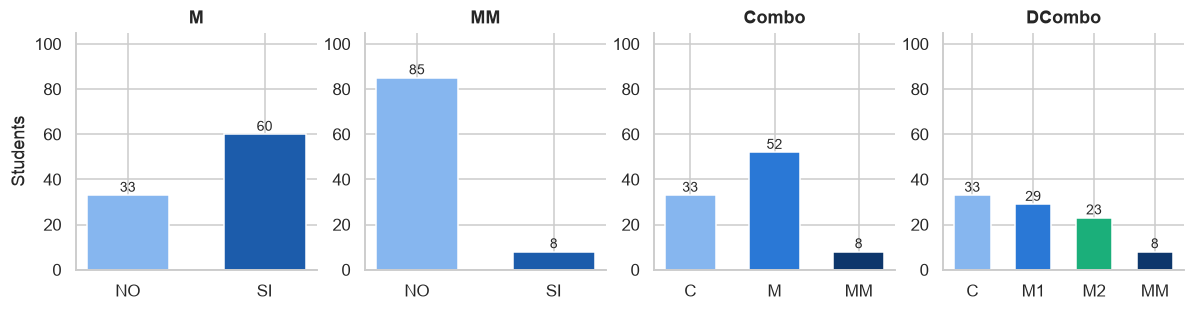

In [7]:
# Number of students in each class of each task (training part)
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, task in zip(axes, TASKS):
    counts = y_train[task].value_counts().reindex(ORDERS[task])
    ax.bar(counts.index, counts.values, color=[COLORS[task][c] for c in counts.index], width=0.6)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 1.5, str(v), ha="center", fontsize=9)
    ax.set_title(task)
    ax.set_ylim(0, 105)
axes[0].set_ylabel("Students")
plt.show()

The classes are **unbalanced**. Only about 9% of the students are severely myopic (`MM` = SI),
so a model that always answers "no" would already be right ~91% of the time. This is why we
report more metrics than accuracy.

## 3. Data preparation

The raw table needs a few fixes before any model can use it. All of them are written in one
function, `clean()`. It works row by row and learns nothing from the data, so it treats the
training, hold-out and test students exactly the same way.

1. **English names** for the columns.
2. **Removed columns:**
   * an empty column (`hº act.cerca sem`, 100% missing);
   * the examination date, which has no plausible effect on myopia;
   * the free-text ancestry fields, with dozens of different answers for 132 students. The
     students come from the University of Navarra, so Navarra will always be the most common
     answer, and no conclusion could be drawn from it;
   * an undocumented column that has the same value in almost every row (`Grupo fot`);
   * the original indoor/outdoor ratio: it cannot be computed for students with 0 outdoor
     hours (it held arbitrary values), and both hour totals are already kept;
   * five "average" columns that are **one single column divided by 2 or by 4** (checked
     below). Dividing by a number only changes the units: once the variables are put on the
     same scale (Section 6), each of them is exactly the same column as its total, so it
     cannot add anything.
3. **Kept on purpose:** the columns that **combine several columns**:
   * total outdoor hours (3 activities) and total indoor hours (2 activities);
   * average eye length (the 2 eyes);
   * total sun marker (2 eyes, and 2 areas of the eye).

   A combination of several columns can carry information that no part has on its own, so
   they are kept and Lasso decides which ones are useful (Section 5).
4. **Fixed:** an hour column that is missing but can be computed exactly from the others is
   filled in.
5. **Text answers turned into numbers:** yes/no → 1/0, never/sometimes/always → 0/1/2,
   "father, mother, siblings" → separate indicators.

The few values that are still missing are filled later, **inside each model**, with the
median of the students the model is trained on.

In [8]:
# The "average" columns are exactly a total divided by 2 or by 4 (largest difference over the training part):
checks = {"OD-Media = OD-Total / 2": X_train["OD-Media"] - X_train["OD-Total"] / 2,
          "OS-Media = OS-Total / 2": X_train["OS-Media"] - X_train["OS-Total"] / 2,
          "CUVAF-Media = CUVAF-Total / 4": X_train["CUVAF-Media"] - X_train["CUVAF-Total"] / 4,
          "Promedio Nasal = Suma Nasal / 2": X_train["Promedio Nasal"] - X_train["Suma Nasal"] / 2,
          "Promedio Temporal = Suma Temporal / 2": X_train["Promedio Temporal"] - X_train["Suma Temporal"] / 2}
pd.Series({k: v.abs().max() for k, v in checks.items()}, name="largest difference").to_frame()

,largest difference
OD-Media = OD-Total / 2,5.000000e-09
OS-Media = OS-Total / 2,2.000000e-09
CUVAF-Media = CUVAF-Total / 4,5.000000e-09
Promedio Nasal = Suma Nasal / 2,5.000000e-09
Promedio Temporal = Suma Temporal / 2,5.000000e-09


In [9]:
NAMES = {
    "edad": "age", "hº deporte sem": "sport_h", "hº naturaleza sem": "nature_h",
    "hº ocio exteriores sem": "outdoor_leisure_h", "horas exterior sem": "outdoor_total_h",
    "hº estudiar sem": "study_h", "hº ocio inter sem": "indoor_leisure_h", "horas interior sem": "indoor_total_h",
    "Familiar miope num.": "myopic_parents", "LA OD": "eye_length_right", "LA OS": "eye_length_left",
    "LA Media": "eye_length_mean", "Querato OD": "curvature_right_1", "Querato OD Eje2": "curvature_right_2",
    "Querato OS": "curvature_left_1", "Querato OS Eje 2": "curvature_left_2",
    "OD-Total": "sun_marker_right", "OD-DS": "sun_marker_right_sd", "OS-Total": "sun_marker_left",
    "OS-DS": "sun_marker_left_sd", "CUVAF-Total": "sun_marker_total", "CUVAF-DS": "sun_marker_sd",
    "Suma Nasal": "sun_marker_inner", "DE Nasal": "sun_marker_inner_sd",
    "Suma Temporal": "sun_marker_outer", "DE Temporal": "sun_marker_outer_sd",
}
YES_NO = {"Exterior Mucho": "says_outdoors_a_lot", "Interior Mcho": "says_indoors_a_lot",
          "fumador": "smoker", "toma sol": "sunbathes", "protege sol": "uses_sun_protection"}


def clean(raw):
    """Raw table (train, hold-out or test) -> numeric table with English names. Learns nothing."""
    df = pd.DataFrame({new: raw[old] for old, new in NAMES.items()})
    # fill an hour column exactly when it can be computed from the others
    parts = ["sport_h", "nature_h", "outdoor_leisure_h"]
    for col in parts:
        others = [c for c in parts if c != col]
        df[col] = df[col].fillna(df["outdoor_total_h"] - df[others].sum(axis=1, min_count=2))
    df["indoor_total_h"] = df["indoor_total_h"].fillna(df["study_h"] + df["indoor_leisure_h"])
    # text answers -> numbers
    df["male"] = (raw["sexo"] == "Hombre").astype(int)
    for old, new in YES_NO.items():
        df[new] = (raw[old] == "SI").astype(int)
    df["screens_before_sleep"] = raw["disp.elec.antes dormir"].map({"Nunca": 0, "A veces": 1, "Siempre": 2})
    df["skin_type"] = pd.to_numeric(raw["fototipo"].astype("string").str.extract(r"(\d)", expand=False),
                                    errors="coerce")  # 'E'/'L' are not skin types -> missing
    family = raw["familiar miope"].fillna("No lo se")
    df["myopic_siblings"] = family.str.contains("Hermanos").astype(int)
    df["family_unknown"] = family.str.contains("No lo se").astype(int)
    df["family_severe_myopia"] = (raw["Familiar MM SI/NO"] == "Si").astype(int)
    df["family_severe_unknown"] = (raw["Familiar MM SI/NO"] == "No lo se").astype(int)
    df["retina_problem"] = raw["pat. Ret. Miop magna"].fillna("").str.startswith("S").astype(int)
    df["retina_problem_unknown"] = (raw["pat. Ret. Miop magna"] == "No lo se").astype(int)
    return df.astype(float)


train_clean = clean(X_train)
print(f"{train_clean.shape[1]} columns after cleaning. Missing values in the training part:")
print(train_clean.isna().sum()[train_clean.isna().sum() > 0].to_dict())

40 columns after cleaning. Missing values in the training part:
{'myopic_parents': 3, 'skin_type': 44}


## 4. Exploratory analysis

Only the 93 students of the training part are used here. We look for the variables that
differ between the groups, without assuming anything in advance.

In [10]:
# Table for the exploration: cleaned training data, the DCombo group and two summaries of the eyes
eda = train_clean.assign(
    DCombo=pd.Categorical(y_train["DCombo"], categories=DCOMBO_ORDER),
    curvature_mean=train_clean[["curvature_right_1", "curvature_right_2",
                                "curvature_left_1", "curvature_left_2"]].mean(axis=1),
    longest_eye=train_clean[["eye_length_right", "eye_length_left"]].max(axis=1))

### 4.1 Eye measurements

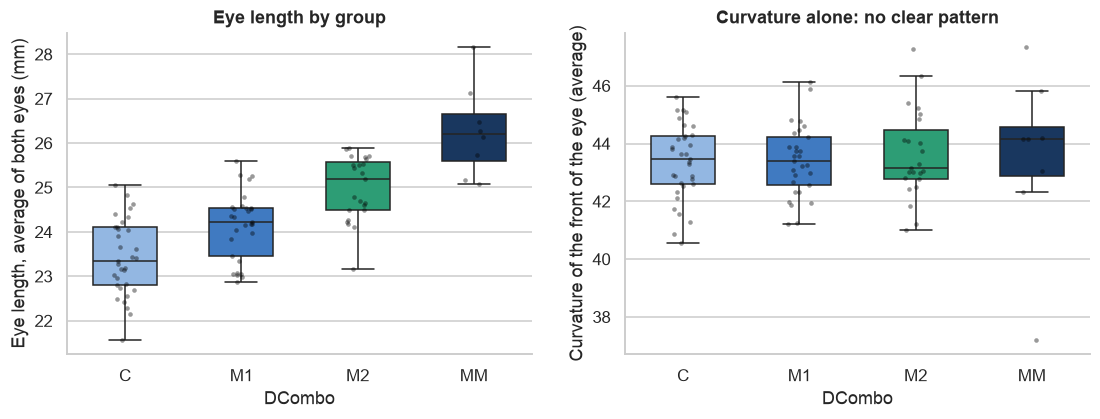

In [11]:
# Eye length and curvature in each DCombo group
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (col, label) in zip(axes, [("eye_length_mean", "Eye length, average of both eyes (mm)"),
                                   ("curvature_mean", "Curvature of the front of the eye (average)")]):
    sns.boxplot(data=eda, x="DCombo", y=col, hue="DCombo", palette=DCOMBO_COLORS, legend=False, ax=ax,
                width=0.55, fliersize=0, dodge=False)
    sns.stripplot(data=eda, x="DCombo", y=col, color="black", size=3, alpha=0.4, ax=ax)
    ax.set_ylabel(label)
axes[0].set_title("Eye length by group")
axes[1].set_title("Curvature alone: no clear pattern")
plt.show()

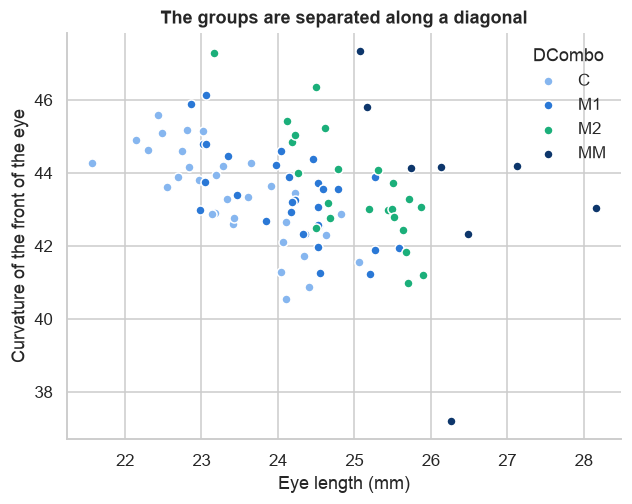

In [12]:
# Eye length against curvature, coloured by group
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for cls in DCOMBO_ORDER:
    sub = eda[eda["DCombo"] == cls]
    ax.scatter(sub["eye_length_mean"], sub["curvature_mean"], s=35, color=DCOMBO_COLORS[cls],
               edgecolor="white", label=cls)
ax.set_xlabel("Eye length (mm)")
ax.set_ylabel("Curvature of the front of the eye")
ax.set_title("The groups are separated along a diagonal")
ax.legend(title="DCombo")
plt.show()

* **Eye length is the variable that differs most between groups.** The C students have the
  shortest eyes and the MM students the longest; on average, M2 students have longer eyes
  than M1 students. The groups overlap.
* **Curvature alone barely changes** between groups. But in the scatter plot the groups are
  separated along a **diagonal**: at the same length, a more curved eye is more often myopic.
  It is the **combination** of length and curvature that matters, which suggests a new
  variable, *length × curvature* (Section 5).

### 4.2 Family, lifestyle and sun exposure

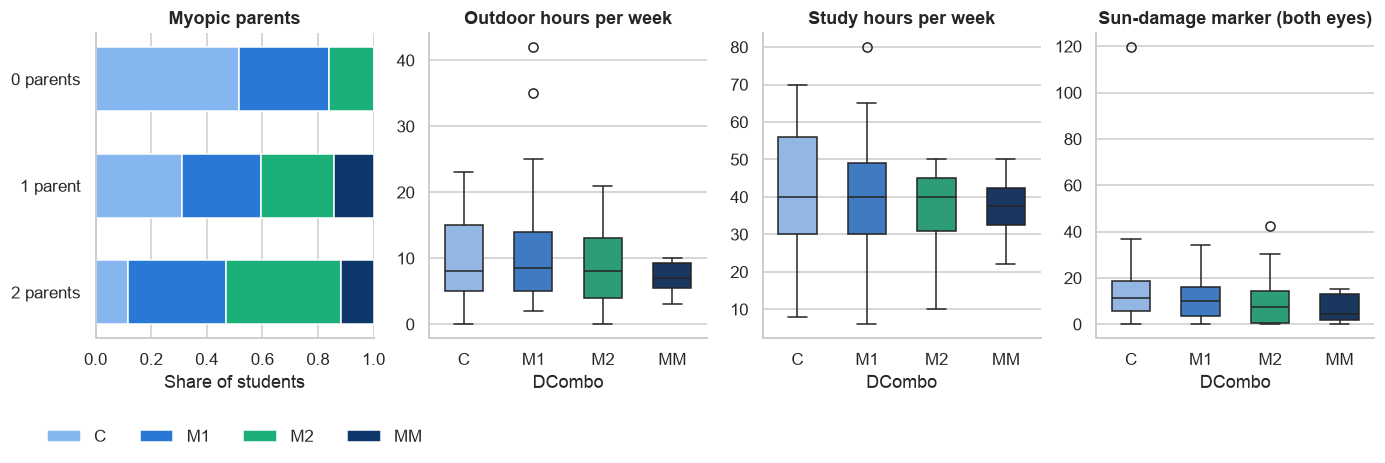

In [13]:
# Groups by number of myopic parents, and outdoor hours, study hours and sun marker by group
parents = eda["myopic_parents"].map({0: "0 parents", 1: "1 parent", 2: "2 parents"}).fillna("unknown")
share = pd.crosstab(parents, eda["DCombo"], normalize="index").reindex(["0 parents", "1 parent", "2 parents"])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
left = np.zeros(len(share))
for cls in DCOMBO_ORDER:
    axes[0].barh(share.index, share[cls], left=left, color=DCOMBO_COLORS[cls], label=cls, height=0.6)
    left += share[cls].to_numpy()
axes[0].invert_yaxis()
axes[0].set_xlabel("Share of students")
axes[0].set_title("Myopic parents")
axes[0].legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
for ax, (col, title) in zip(axes[1:], [("outdoor_total_h", "Outdoor hours per week"),
                                       ("study_h", "Study hours per week"),
                                       ("sun_marker_total", "Sun-damage marker (both eyes)")]):
    sns.boxplot(data=eda, x="DCombo", y=col, hue="DCombo", palette=DCOMBO_COLORS, legend=False, ax=ax,
                width=0.55, dodge=False)
    ax.set_title(title)
    ax.set_ylabel("")
plt.show()

* **Family:** the more myopic parents, the more myopia among the students (52% without
  myopia with no myopic parents, 12% with two). Severe myopia (`MM`) only appears among
  students with at least one myopic parent.
* **Time outdoors and sun marker:** the severely myopic students spend somewhat fewer hours
  outdoors and have less sun damage on the eye. The differences
  are small and the groups overlap a lot.
* **Study hours** look the same in every group.

### 4.3 Severe myopia and the longest eye

The average of the two eyes can hide a single very long eye, so we also look at the
longest of each student's two eyes:

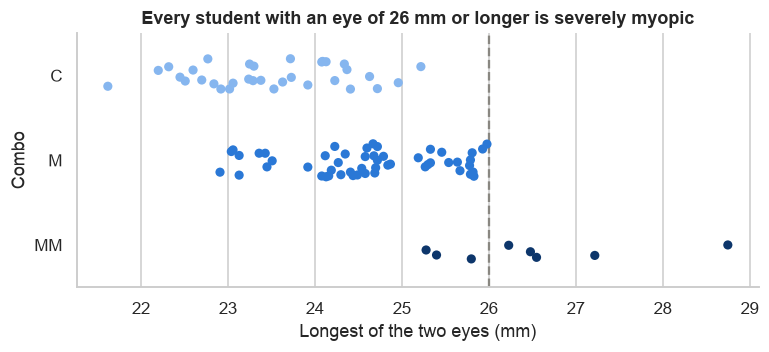

Combo,C,M,MM
longest eye >= 26 mm,,,
False,33,52,3
True,0,0,5


Longest eye of a student who is not MM: 25.98 mm | next MM student: 26.23 mm


In [14]:
# Longest of the two eyes in each Combo group, with the 26 mm line
fig, ax = plt.subplots(figsize=(8, 3))
sns.stripplot(x=eda["longest_eye"], y=y_train["Combo"], order=COMBO_ORDER, hue=y_train["Combo"],
              hue_order=COMBO_ORDER, palette=COMBO_COLORS, size=6, jitter=0.2, legend=False, ax=ax)
ax.axvline(26, color=GREY, linestyle="--")
ax.set(xlabel="Longest of the two eyes (mm)", ylabel="Combo",
       title="Every student with an eye of 26 mm or longer is severely myopic")
plt.show()
display(pd.crosstab(eda["longest_eye"] >= 26, y_train["Combo"], rownames=["longest eye >= 26 mm"])[COMBO_ORDER])

longest_not_mm = eda.loc[y_train["Combo"] != "MM", "longest_eye"].max()
next_mm = eda.loc[(y_train["Combo"] == "MM") & (eda["longest_eye"] > longest_not_mm), "longest_eye"].min()
print(f"Longest eye of a student who is not MM: {longest_not_mm:.2f} mm | next MM student: {next_mm:.2f} mm")

* **Every student with an eye of 26 mm or longer is severely myopic (`MM`)**, and nobody
  else reaches that length. Below 26 mm the groups mix, so this rule only covers part of the
  `MM` students.
* 26 mm is a round number in the gap printed above. With so few students the exact cut-off is
  only approximate.
* New variables suggested: *longest eye* and *longest eye ≥ 26 mm* (Section 5).

### 4.4 Which variables move with myopia?

For each variable we compute its (Spearman) correlation with `M` and with `MM`, written as
1 = SI and 0 = NO. `Combo` summarises these two columns, so together they cover it.
* 0 means no relation. A positive value means the variable tends to be higher in the students
  with SI; a negative one, that it tends to be lower.
* Spearman sorts the students by the variable and checks whether those with SI tend to come
  before or after those with NO. It only uses the order, not the size of the values, so a few
  extreme values (e.g. a student with many hours outdoors) cannot dominate the result.

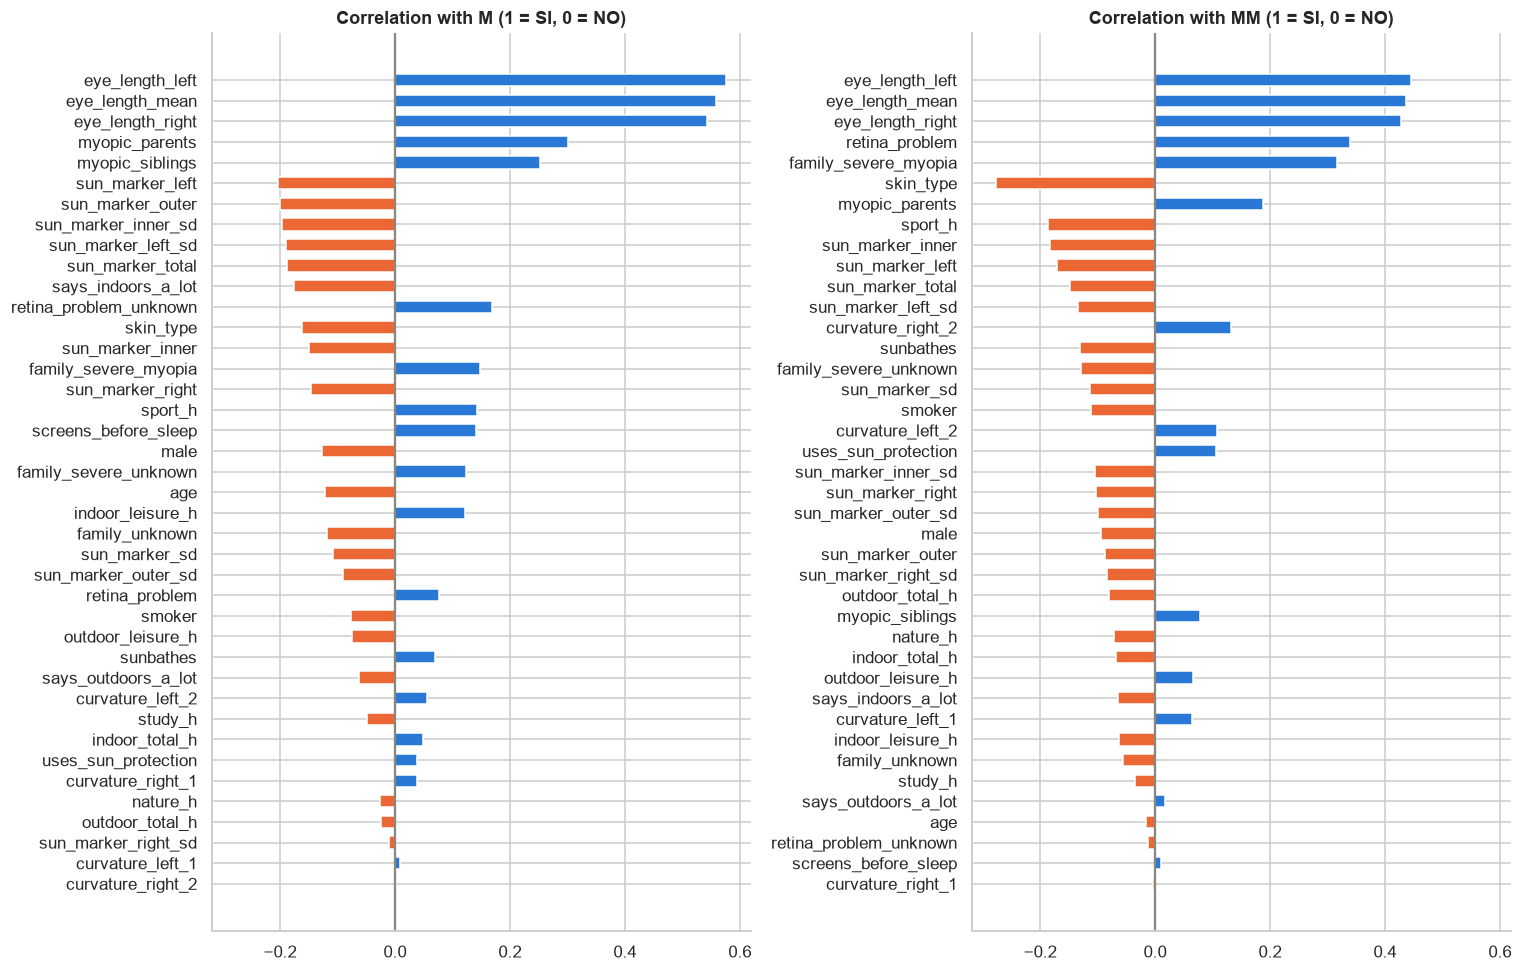

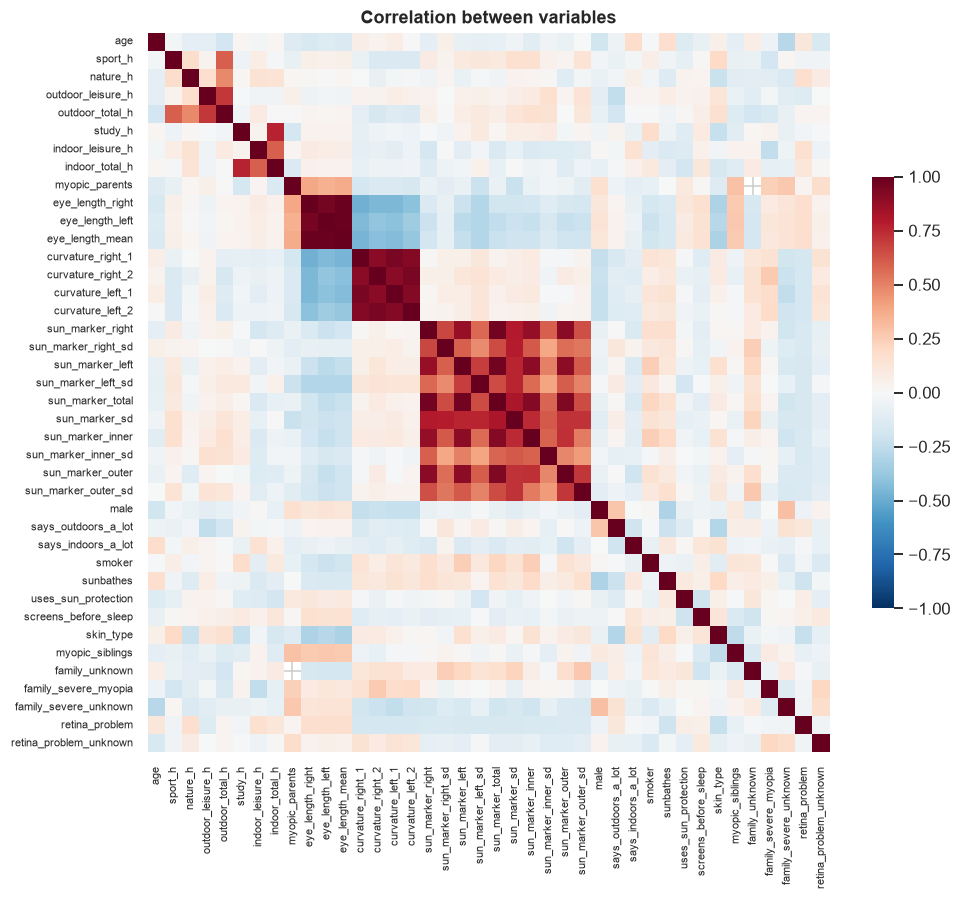

In [15]:
targets = pd.DataFrame({"M": (y_train["M"] == "SI").astype(int), "MM": (y_train["MM"] == "SI").astype(int)})
corr = pd.DataFrame({task: train_clean.corrwith(targets[task], method="spearman") for task in targets}).dropna()

# One ranking per target: strongest relation (positive or negative) at the top
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharex=True)
for ax, task in zip(axes, ["M", "MM"]):
    ranked = corr[task].reindex(corr[task].abs().sort_values().index)
    ax.barh(ranked.index, ranked.values, color=[BLUE if v > 0 else ORANGE for v in ranked], height=0.6)
    ax.axvline(0, color=GREY)
    ax.set_title(f"Correlation with {task} (1 = SI, 0 = NO)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(train_clean.corr(method="spearman"), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6})
ax.set_title("Correlation between variables")
ax.tick_params(labelsize=7)
plt.show()

**Takeaways of the exploration**

1. **A few variables carry almost all the signal:**
   * **eye length** is the strongest, for both questions (and, from Section 4.1, its
     combination with curvature);
   * **family history** comes next: myopic parents and siblings go with myopia (`M`), while
     a relative with severe myopia and retina problems go with severe myopia (`MM`);
   * the sun marker and the skin type show a weak negative relation;
   * most other variables (study hours, smoking, screens, sun protection…) show none.
2. **Many columns are near-duplicates** (the red blocks of the heatmap): the two eyes, the
   sun-marker measurements, and the totals and their parts.
3. **We have about 40 variables for 93 students.** With so few students, every useless variable
   is one more chance for a model to learn noise.

## 5. New variables and variable selection

### 5.1 New variables (from the exploration)

| New variable | Where it comes from |
|---|---|
| `length_x_curvature` | Section 4.1: the groups separate along a diagonal of length and curvature |
| `longest_eye` | Section 4.3: severe myopia shows up in the longest of the two eyes |
| `long_eye_26` (1 if longest eye ≥ 26 mm) | Section 4.3: every student above 26 mm is `MM` |

`prepare()` = `clean()` + these new variables. Like `clean()`, it learns nothing from the
data.

In [16]:
# The three new variables suggested by the exploration (table above)
def add_features(df):
    df = df.copy()
    curvature = df[["curvature_right_1", "curvature_right_2", "curvature_left_1", "curvature_left_2"]].mean(axis=1)
    df["length_x_curvature"] = df["eye_length_mean"] * curvature
    df["longest_eye"] = df[["eye_length_right", "eye_length_left"]].max(axis=1)
    df["long_eye_26"] = (df["longest_eye"] >= 26).astype(float)
    return df


def prepare(raw):
    return add_features(clean(raw))


print(f"{prepare(X_train).shape[1]} variables after preparation")

43 variables after preparation


### 5.2 Selecting the useful variables with Lasso

We have 43 variables for 93 students, many of them near-duplicates. Lasso is a logistic
regression that pays a penalty for every variable it uses, so the variables that do not help
get a weight of zero. The strength of the penalty is set by C, the inverse of the α in the
usual Lasso formula: a small C means a strong penalty, so fewer variables are kept.

We use Lasso to see which variables are useful for each target:
1. Split the training part into 25 subsets (5-fold cross-validation, repeated 5 times).
2. In each subset and for each target: fill the missing values, put the variables on the same
   scale, fit Lasso (C = 0.1) and note which variables keep a non-zero weight.
3. Count, for each variable and target, in how many of the 25 subsets it was kept.

The heatmap shows the variables kept at least 20% of the times; the list below it, the ones
never kept.

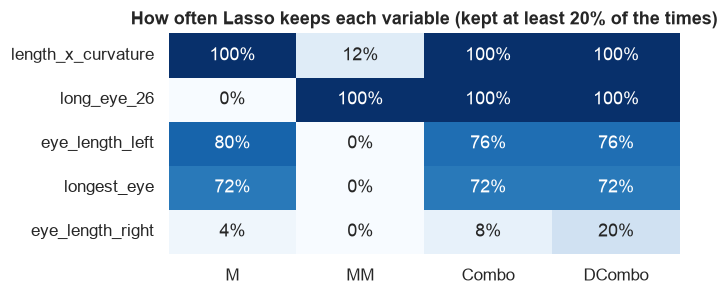

Never kept for any task (33 of 43): age, nature_h, outdoor_leisure_h, outdoor_total_h, study_h, indoor_leisure_h, indoor_total_h, myopic_parents, curvature_right_1, curvature_right_2, curvature_left_1, curvature_left_2, sun_marker_right, sun_marker_left, sun_marker_left_sd, sun_marker_total, sun_marker_sd, sun_marker_inner, sun_marker_inner_sd, sun_marker_outer, sun_marker_outer_sd, male, says_outdoors_a_lot, says_indoors_a_lot, smoker, sunbathes, uses_sun_protection, screens_before_sleep, skin_type, family_unknown, family_severe_myopia, family_severe_unknown, retina_problem


In [17]:
# Lasso as a pipeline step, and how often it keeps each variable over the 25 subsets
from joblib import Parallel, delayed, parallel_config
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import FunctionTransformer, Pipeline
from sklearn.preprocessing import StandardScaler


class LassoSelector(TransformerMixin, BaseEstimator):
    """Keeps the variables with a non-zero weight in an L1-penalised (Lasso) logistic regression."""

    def __init__(self, C=0.3):
        self.C = C

    def fit(self, x, y):
        c = self.C
        while True:  # if the penalty is so strong that nothing survives, relax it
            lasso = LogisticRegression(l1_ratio=1.0, solver="saga", C=c, tol=1e-3, max_iter=10000,
                                       random_state=SEED).fit(x, y)
            self.support_ = np.abs(lasso.coef_).max(axis=0) > 1e-8
            if self.support_.any() or c > 100:
                return self
            c *= 3

    def transform(self, x):
        return np.asarray(x)[:, self.support_]


FEATURES = list(prepare(X_train).columns)
cv_splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
                 .split(X_train, y_train["DCombo"]))


def kept(task, train_idx):
    selector = Pipeline([("prepare", FunctionTransformer(prepare)), ("fill", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler()), ("lasso", LassoSelector(C=0.1))])
    selector.fit(X_train.iloc[train_idx], y_train[task].iloc[train_idx])
    return selector.named_steps["lasso"].support_


with parallel_config(backend="loky", inner_max_num_threads=1):
    frequency = pd.DataFrame({task: np.mean(Parallel(n_jobs=-1)(delayed(kept)(task, tr) for tr, _ in cv_splits),
                                            axis=0) for task in TASKS}, index=FEATURES)
shown = frequency[frequency.max(axis=1) >= 0.2].sort_values("DCombo", ascending=False)
fig, ax = plt.subplots(figsize=(6, 0.32 * len(shown) + 1))
sns.heatmap(shown, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title("How often Lasso keeps each variable (kept at least 20% of the times)")
plt.show()
never = frequency.index[frequency.max(axis=1) == 0]
print(f"Never kept for any task ({len(never)} of {len(FEATURES)}):", ", ".join(never))

With this penalty, Lasso keeps **only eye measurements and the three new variables**. The other
variables are dropped in (almost) every round.

* **`length_x_curvature` is kept in every round for `M`, `Combo` and `DCombo`**, while the four
  curvature columns on their own are never kept. As Section 4.1 suggested, it is the combination
  that matters.
* **`long_eye_26` is kept in every round for `MM`, `Combo` and `DCombo`, and never for `M`.** This
  matches Section 4.3: it marks severe myopia, not myopia itself. For `MM` it is almost always the
  only variable kept.
* Among the near-duplicate length columns (left eye, right eye, longest eye), Lasso keeps one or
  two, never all of them.
* **Family history is (almost) never kept**, although Section 4.2 showed it is related to
  myopia. Once the eye length is known it adds little: students with myopic parents tend to have
  longer eyes, so the information is already there.
* All lifestyle, sun-exposure and habit variables are dropped.

The tuning of each model also tries a weaker penalty (C = 1), which lets a few more variables in.
It picks whichever strength predicts best for each task.

## 6. Models

### 6.1 Candidates and why

We try a few models, each for a reason:

| Model | Why it can be the best | Tasks |
|---|---|---|
| **Logistic regression** | The exploration shows gradual, one-directional relations (longer eye → more myopia). With 93 students, a linear model with few parameters is hard to beat. | all |
| **Random forest** | Finds thresholds and combinations on its own (e.g. "eye ≥ 26 mm"). It averages many trees, so it is robust to useless variables. | all |
| **XGBoost** | Gradient boosting is usually the strongest family on tabular data. Shallow trees and a moderate learning rate keep it from memorising 93 students. | all |

For `MM`, where only ~9% of the students are positive, the tuning can also give more weight to
the rare class.

**Other models that we did not try:**
* **Linear regression:** predicts a number, not a class: with yes/no it can give "probabilities"
  below 0 or above 1 (logistic regression is its version for classification).
* **SVM:** with a linear boundary it behaves like logistic regression; a curved one adds
  flexibility, which the random forest and XGBoost already test.
* **kNN:** irrelevant variables distort the distances with so few students, and its
  probabilities jump in steps.
* **Single decision tree:** very unstable with 93 students; the random forest is its improved
  version.

**Pipeline.** Every model is the last step of the same pipeline:

`prepare()` → fill missing values (median) → **scale** (mean 0, standard deviation 1) →
**Lasso selection** → model

**Tuning.** For each model a small set of settings (including the Lasso strength) is tried with
an inner 3-fold cross-validation inside each training fold (nested cross-validation), and the
best one by accuracy is kept.

**Evaluation.** We use 5-fold cross-validation repeated 5 times (25 rounds) on the 93 training
students. The folds keep the label proportions. We report:
* accuracy;
* precision, recall and F1-score (for the class SI in `M`/`MM`; averaged over classes in
  `Combo`/`DCombo`);
* ROC AUC;
* MSE of the predicted probabilities: the true class is written as 1 and the other classes as 0,
  and we average the squared differences with the probabilities given by the model. 0 is
  perfect; a model that is confident and wrong is punished most. It does not depend on the
  threshold.

We also draw ROC and precision-recall curves. **The model of each task is chosen by
accuracy.**

**Threshold (operating point).** In the yes/no tasks (`M`, `MM`) a model gives a probability, and
it answers SI when that probability exceeds a threshold. The usual threshold is 0.5. For each
model we try thresholds from 0.20 to 0.80 on its cross-validation predictions and keep the most
accurate one, so that every model is compared at its best. In `Combo` and `DCombo` there is no
threshold: the most likely group is chosen.

In [18]:
# Libraries for the models, the metrics and the tuning
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, mean_squared_error, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier

# Inner cross-validation (3 parts) used to choose the settings of each model
INNER_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


# XGBoost wrapper: turns the text labels into numbers and back, so it works like any scikit-learn model
class XGBoostModel(ClassifierMixin, BaseEstimator):
    """XGBoost with text labels (the library itself only accepts 0, 1, 2, ...)."""

    def __init__(self, max_depth=2, scale_pos_weight=1.0):
        self.max_depth, self.scale_pos_weight = max_depth, scale_pos_weight

    def fit(self, x, y):
        self.classes_, codes = np.unique(y, return_inverse=True)
        self.model_ = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=self.max_depth,
                                    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=self.scale_pos_weight,
                                    n_jobs=1, random_state=SEED, verbosity=0).fit(x, codes)
        return self

    def predict_proba(self, x):
        return self.model_.predict_proba(x)

    def predict(self, x):
        return self.classes_[self.predict_proba(x).argmax(axis=1)]


# The 5 steps every model goes through: clean -> fill missing values -> scale -> Lasso -> model
def pipeline(model):
    return Pipeline([("prepare", FunctionTransformer(prepare)), ("fill", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()), ("lasso", LassoSelector()), ("model", model)])


# The 3 candidate models of a task, each with the settings to try (in MM, also more weight to the rare class)
def candidates(task):
    """The candidate models of a task, each with its small tuning grid (Lasso strength + model settings)."""
    rare = task == "MM"
    weights = {"model__class_weight": [None, "balanced"]} if rare else {}
    models = {
        "Logistic regression": (LogisticRegression(max_iter=5000), {"model__C": [0.1, 1.0], **weights}),
        "Random forest": (RandomForestClassifier(n_estimators=150, random_state=SEED),
                          {"model__min_samples_leaf": [1, 5], **weights}),
        "XGBoost": (XGBoostModel(), {"model__max_depth": [2, 3],
                                     **({"model__scale_pos_weight": [1.0, 5.0]} if rare else {})}),
    }
    return {name: GridSearchCV(pipeline(model), {"lasso__C": [0.1, 1.0], **grid}, cv=INNER_CV,
                               scoring="accuracy")
            for name, (model, grid) in models.items()}

In [19]:
# Name of the reference model, which always predicts the most frequent class
BASELINE = "Baseline (most frequent class)"


# Train a model on the training students of one round and predict that round's validation students
def run_fold(model, task, train_idx, test_idx):
    fitted = clone(model).fit(X_train.iloc[train_idx], y_train[task].iloc[train_idx])
    proba = fitted.predict_proba(X_train.iloc[test_idx]) if hasattr(fitted, "predict_proba") else None
    return fitted.predict(X_train.iloc[test_idx]), proba, fitted.classes_


# MSE of the predicted probabilities: the true class is written as 1 and the other classes as 0
def mse(truth, proba, classes):
    if proba is None:
        return np.nan
    onehot = (np.asarray(truth)[:, None] == np.asarray(classes)[None, :]).astype(float)
    return mean_squared_error(onehot, proba)


# Accuracy, precision, recall, F1, ROC AUC and MSE of one round
def metrics(task, truth, pred, proba, classes):
    truth, pred = np.asarray(truth), np.asarray(pred)
    if task in ("M", "MM"):
        out = {"accuracy": accuracy_score(truth, pred),
               "precision": precision_score(truth, pred, pos_label="SI", zero_division=0),
               "recall": recall_score(truth, pred, pos_label="SI", zero_division=0),
               "F1": f1_score(truth, pred, pos_label="SI", zero_division=0)}
        score = None if proba is None else proba[:, list(classes).index("SI")]
        out["ROC AUC"] = roc_auc_score(truth == "SI", score) if score is not None and len(set(truth)) == 2 else np.nan
    else:
        out = {"accuracy": accuracy_score(truth, pred),
               "precision": precision_score(truth, pred, average="macro", zero_division=0),
               "recall": recall_score(truth, pred, average="macro", zero_division=0),
               "F1": f1_score(truth, pred, average="macro", zero_division=0)}
        try:
            out["ROC AUC"] = roc_auc_score(truth, proba, multi_class="ovr", labels=classes)
        except (ValueError, TypeError):
            out["ROC AUC"] = np.nan
    out["MSE"] = mse(truth, proba, classes)
    return out


# Every combination to evaluate (task x model x round), run in parallel
jobs = [(task, name, model, k, tr, te)
        for task in TASKS
        for name, model in {BASELINE: DummyClassifier(strategy="most_frequent"), **candidates(task)}.items()
        for k, (tr, te) in enumerate(cv_splits)]
with parallel_config(backend="loky", inner_max_num_threads=1):
    outputs = Parallel(n_jobs=-1)(delayed(run_fold)(model, task, tr, te) for task, name, model, k, tr, te in jobs)

# Collect the metrics of every round and the out-of-fold predictions
folds = []   # one row per (task, model, fold) with its metrics
oof = {}     # out-of-fold predictions and probabilities, for the curves and the threshold
for (task, name, model, k, tr, te), (pred, proba, classes) in zip(jobs, outputs):
    folds.append({"task": task, "model": name, "fold": k,
                  **metrics(task, y_train[task].iloc[te], pred, proba, classes)})
    store = oof.setdefault((task, name), {"idx": [], "pred": [], "proba": [], "classes": classes})
    store["idx"].append(te)
    store["pred"].append(pred)
    store["proba"].append(proba)
folds = pd.DataFrame(folds)

# Yes/no tasks: tune the threshold of each model, then recompute its metrics at that threshold
GRID = np.round(np.arange(0.2, 0.81, 0.05), 2)
model_thresholds = {}
for (task, name), store in oof.items():
    if task not in ("M", "MM") or name == BASELINE:
        continue
    si = list(store["classes"]).index("SI")
    truth = np.concatenate([y_train[task].to_numpy()[idx] == "SI" for idx in store["idx"]])
    score = np.concatenate([proba[:, si] for proba in store["proba"]])
    accs = np.array([((score >= t) == truth).mean() for t in GRID])
    best = GRID[np.flatnonzero(accs == accs.max())]
    model_thresholds[(task, name)] = t = float(best[np.argmin(np.abs(best - 0.5))])  # ties -> closest to 0.5
    for k, (idx, proba) in enumerate(zip(store["idx"], store["proba"])):
        store["pred"][k] = np.where(proba[:, si] >= t, "SI", "NO")
        fold_metrics = metrics(task, y_train[task].iloc[idx], store["pred"][k], proba, store["classes"])
        row = (folds["task"] == task) & (folds["model"] == name) & (folds["fold"] == k)
        folds.loc[row, list(fold_metrics)] = list(fold_metrics.values())

# Average of the 25 rounds per task and model, shown as one table per task
summary = folds.groupby(["task", "model"], sort=False).mean(numeric_only=True).drop(columns="fold")
summary.insert(0, "threshold", [model_thresholds.get(key, np.nan) for key in summary.index])
summary.insert(2, "accuracy std", folds.groupby(["task", "model"], sort=False)["accuracy"].std())
for task in TASKS:
    print(f"\n{task}")
    display(summary.loc[task].sort_values("accuracy", ascending=False).style.format("{:.3f}", na_rep="—")
            .highlight_max(subset=["accuracy"], color="#cde2fb"))


M


,threshold,accuracy,accuracy std,precision,recall,F1,ROC AUC,MSE
model,,,,,,,,
Logistic regression,0.600,0.804,0.069,0.879,0.813,0.842,0.876,0.147
XGBoost,0.550,0.770,0.087,0.857,0.780,0.814,0.845,0.165
Random forest,0.500,0.770,0.075,0.815,0.843,0.825,0.849,0.155
Baseline (most frequent class),—,0.646,0.018,0.646,1.000,0.785,0.500,0.354



MM


,threshold,accuracy,accuracy std,precision,recall,F1,ROC AUC,MSE
model,,,,,,,,
Logistic regression,0.600,0.964,0.033,0.760,0.580,0.640,0.806,0.068
Random forest,0.400,0.964,0.033,0.693,0.660,0.651,0.835,0.045
XGBoost,0.250,0.953,0.032,0.667,0.540,0.565,0.835,0.051
Baseline (most frequent class),—,0.915,0.025,0.000,0.000,0.000,0.500,0.085



Combo


,threshold,accuracy,accuracy std,precision,recall,F1,ROC AUC,MSE
model,,,,,,,,
Logistic regression,—,0.753,0.106,0.719,0.686,0.689,0.885,0.119
XGBoost,—,0.732,0.089,0.717,0.688,0.689,0.870,0.131
Random forest,—,0.712,0.074,0.640,0.633,0.622,0.875,0.126
Baseline (most frequent class),—,0.560,0.042,0.187,0.333,0.239,0.500,0.293



DCombo


,threshold,accuracy,accuracy std,precision,recall,F1,ROC AUC,MSE
model,,,,,,,,
Logistic regression,—,0.631,0.090,0.616,0.605,0.596,0.865,0.120
XGBoost,—,0.581,0.090,0.586,0.570,0.562,0.822,0.149
Random forest,—,0.568,0.083,0.567,0.570,0.557,0.827,0.140
Baseline (most frequent class),—,0.354,0.018,0.089,0.250,0.131,0.500,0.323


* **Every model clearly beats the baseline** in every task.
* **`M`:** logistic regression is the best (0.804), clearly ahead of the random forest and XGBoost
  (0.770).
* **`MM`:** logistic regression and the random forest tie (0.964), and the random forest wins on
  F1-score. Accuracy is only 5 points above always answering "no" (0.915). Precision and recall
  show the real picture: the models find about 55-65% of the severe cases.
* **`Combo`:** logistic regression is the best (0.753), ahead of XGBoost (0.732).
* **`DCombo`:** logistic regression is the best (0.631), well ahead of XGBoost (0.581) and the
  random forest (0.568). It is the hardest task: four groups whose eye lengths overlap
  (Section 4.1).
* **MSE** (last column) points to the same best model as accuracy in every task. In `MM`, where
  logistic regression and the random forest tie on accuracy, it also favours the random forest
  (0.045 vs. 0.068): its probabilities are closer to the truth.
* The differences between the best models are small compared with the variation from one round
  to another (3-11 points). With 93 students, **logistic regression is the best (or tied) in every
  task**: the tree models gain nothing from their extra flexibility.

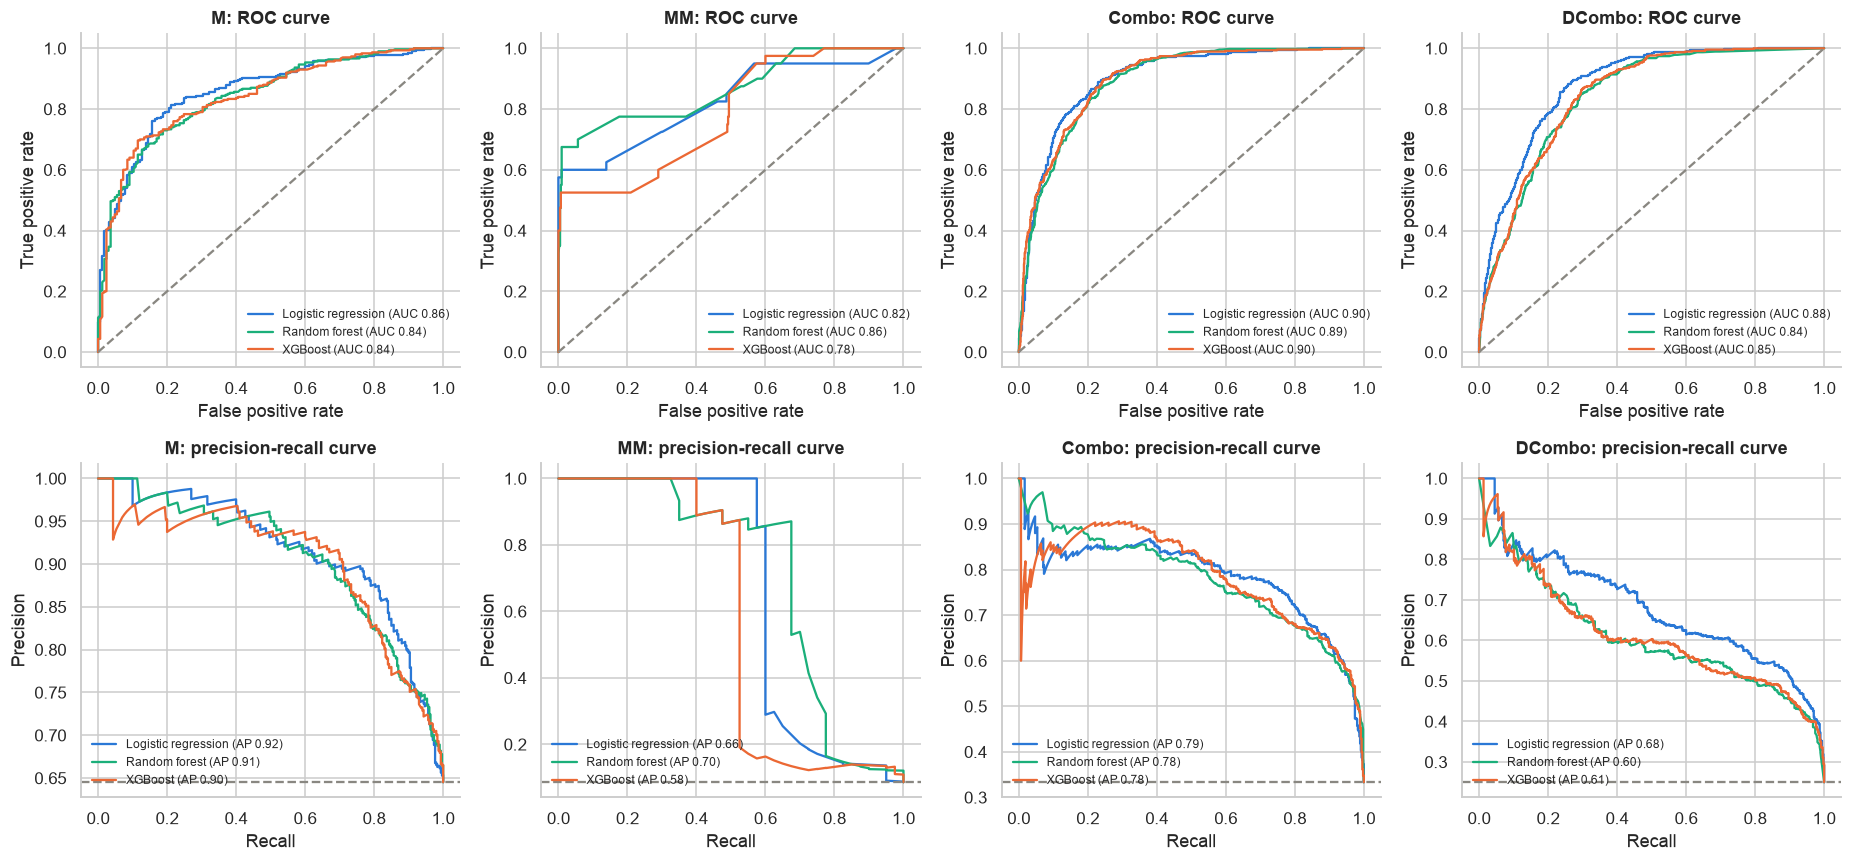

In [20]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve
from sklearn.preprocessing import label_binarize


# True labels and predicted probabilities of all rounds for one task and model 
# (input for the ROC and precision-recall curves)
def curve_inputs(task, name):
    store = oof[(task, name)]
    truth = y_train[task].to_numpy()[np.concatenate(store["idx"])]
    proba = np.vstack(store["proba"])
    if task in ("M", "MM"):
        return (truth == "SI").astype(int), proba[:, list(store["classes"]).index("SI")]
    # several classes: pool the one-vs-rest problems of all classes ("micro-average")
    return label_binarize(truth, classes=store["classes"]).ravel(), proba.ravel()


fig, axes = plt.subplots(2, 4, figsize=(17, 8))
model_colors = {"Logistic regression": BLUE, "Random forest": GREEN, "XGBoost": ORANGE}
for col, task in enumerate(TASKS):
    for name, color in model_colors.items():
        truth, score = curve_inputs(task, name)
        fpr, tpr, _ = roc_curve(truth, score)
        prec, rec, _ = precision_recall_curve(truth, score)
        axes[0, col].plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(truth, score):.2f})")
        axes[1, col].plot(rec, prec, color=color, label=f"{name} (AP {average_precision_score(truth, score):.2f})")
    axes[0, col].plot([0, 1], [0, 1], color=GREY, linestyle="--")
    axes[1, col].axhline(truth.mean(), color=GREY, linestyle="--")
    axes[0, col].set(title=f"{task}: ROC curve", xlabel="False positive rate", ylabel="True positive rate")
    axes[1, col].set(title=f"{task}: precision-recall curve", xlabel="Recall", ylabel="Precision")
    axes[0, col].legend(fontsize=8, loc="lower right")
    axes[1, col].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

For `Combo` and `DCombo` the curves pool
the "one class against the rest" problems of all classes.

* **`M`, `Combo`, `DCombo`:** the curves of the three models almost overlap (ROC AUC 0.84-0.90).
  They order the students in nearly the same way, from "surely not myopic" to "surely myopic", so
  the small differences in accuracy come from where the line is drawn, not from the models seeing
  different things.
* **`MM`:** the precision-recall curve has a clear shape. Precision is perfect up to about half of
  the severe cases and then collapses. That half are the students with an eye of 26 mm or
  longer, which every model recognises. The other severe cases look like ordinary myopic
  students. Average precision is 0.58-0.70, against 0.09 for random guessing.

### 6.2 Chosen model and operating point per task

For each task we keep the model with the highest cross-validated accuracy (at its own threshold
in `M` and `MM`). If two models tie (same accuracy to three decimals), the one with the higher
F1-score wins.

In [21]:
# Most accurate model of each task (ties broken by F1), shown with its threshold and baseline
def best_model(task):
    table = summary.loc[task].drop(BASELINE)
    tied = table[table["accuracy"].round(3) == table["accuracy"].round(3).max()]
    return tied["F1"].idxmax()  # ties on accuracy are broken by the F1-score


chosen = {task: best_model(task) for task in TASKS}
thresholds = {task: model_thresholds[(task, chosen[task])] for task in ("M", "MM")}
pd.DataFrame([{"task": task, "model": chosen[task], "threshold": thresholds.get(task, np.nan),
               "CV accuracy": summary.loc[(task, chosen[task]), "accuracy"],
               "std across the 25 rounds": summary.loc[(task, chosen[task]), "accuracy std"],
               "CV MSE": summary.loc[(task, chosen[task]), "MSE"],
               "baseline accuracy": summary.loc[(task, BASELINE), "accuracy"]} for task in TASKS]
             ).set_index("task").style.format(precision=3, na_rep="—")

,model,threshold,CV accuracy,std across the 25 rounds,CV MSE,baseline accuracy
task,,,,,,
M,Logistic regression,0.600,0.804,0.069,0.147,0.646
MM,Random forest,0.400,0.964,0.033,0.045,0.915
Combo,Logistic regression,—,0.753,0.106,0.119,0.560
DCombo,Logistic regression,—,0.631,0.090,0.120,0.354


* **Thresholds:** 0.60 for `M`: asking for a bit more certainty before saying SI avoids calling
  borderline students myopic. For `MM`, 0.40 for the random forest.
* **Each model needs its own threshold.** In `MM`, for example, XGBoost's best threshold is 0.25
  and logistic regression's 0.60, because their probabilities are not on the same scale. Comparing
  everyone at 0.5 would have been unfair to some models.
* Compared with always predicting the most frequent class (baseline), the chosen models gain about 16 points
  (`M`), 5 (`MM`), 19 (`Combo`) and 28 (`DCombo`).

### 6.3 Could one model answer everything?

After removing the students with wrong labels (Section 1.1), `DCombo` determines the other three
labels (C → no myopia; M1 and M2 → myopia; MM → severe myopia). One `DCombo` model could
therefore answer all four tasks. We take the predictions of the chosen `DCombo` model in each
cross-validation round, translate them into `M`, `MM` and `Combo`, and compare them with the
dedicated models (with their chosen threshold) on exactly the same students.

The same rule decides: the more accurate option wins. If they tie, reading from `DCombo` wins,
because then the predicted labels always fit together (a student cannot be "no myopia" in one
column and "myopia" in another).

In [22]:
TO_M = {"C": "NO", "M1": "SI", "M2": "SI", "MM": "SI"}
TO_MM = {"C": "NO", "M1": "NO", "M2": "NO", "MM": "SI"}
TO_COMBO = {"C": "C", "M1": "M", "M2": "M", "MM": "MM"}
DERIVED = {"M": TO_M, "MM": TO_MM, "Combo": TO_COMBO}


# Probabilities of M, MM or Combo read from the DCombo probabilities (e.g. P(myopia) = P(M1) + P(M2) + P(MM))
def derived_proba(proba, classes, task):
    return np.column_stack([proba[:, np.array([DERIVED[task][c] == label for c in classes])].sum(axis=1)
                            for label in ORDERS[task]])


# Compare, round by round, the dedicated model of each task with reading it from the DCombo model
dcombo = oof[("DCombo", chosen["DCombo"])]
rows, read_from_dcombo = [], {}
for task, mapping in DERIVED.items():
    own = oof[(task, chosen[task])]
    derived, dedicated, mse_derived, mse_dedicated = [], [], [], []
    for idx, d_pred, d_proba, pred, proba in zip(dcombo["idx"], dcombo["pred"], dcombo["proba"],
                                                 own["pred"], own["proba"]):
        truth = y_train[task].to_numpy()[idx]
        derived.append(np.mean(pd.Series(d_pred).map(mapping).to_numpy() == truth))
        mse_derived.append(mse(truth, derived_proba(d_proba, dcombo["classes"], task), ORDERS[task]))
        mse_dedicated.append(mse(truth, proba, own["classes"]))
        if task in thresholds:  # dedicated yes/no model with its chosen threshold
            pred = np.where(proba[:, list(own["classes"]).index("SI")] >= thresholds[task], "SI", "NO")
        dedicated.append(np.mean(pred == truth))
    acc_derived, acc_dedicated = round(np.mean(derived), 3), round(np.mean(dedicated), 3)
    read_from_dcombo[task] = acc_derived >= acc_dedicated
    rows.append({"task": task, "dedicated model": chosen[task], "accuracy, dedicated": acc_dedicated,
                 "accuracy, read from the DCombo model": acc_derived,
                 "MSE, dedicated": np.mean(mse_dedicated), "MSE, read from the DCombo model": np.mean(mse_derived),
                 "decision": "read from the DCombo model" if read_from_dcombo[task] else "dedicated model"})
pd.DataFrame(rows).set_index("task").style.format(precision=3)

,dedicated model,"accuracy, dedicated","accuracy, read from the DCombo model","MSE, dedicated","MSE, read from the DCombo model",decision
task,,,,,,
M,Logistic regression,0.804,0.798,0.147,0.136,dedicated model
MM,Random forest,0.964,0.957,0.045,0.036,dedicated model
Combo,Logistic regression,0.753,0.764,0.119,0.111,read from the DCombo model


* **`M` and `MM`:** the dedicated models are more accurate (0.804 vs. 0.798 and 0.964 vs. 0.957), so
  they are kept.
* **`Combo`:** reading it from the `DCombo` model is slightly more accurate (0.764 vs. 0.753), so
  `Combo` is read from `DCombo`. That is one model fewer, and `Combo` and `DCombo` always agree.
* By **MSE**, reading from `DCombo` is better in all three tasks (`M` 0.136 vs. 0.147, `MM` 0.036
  vs. 0.045, `Combo` 0.111 vs. 0.119): its probabilities, added up, are a bit closer to the truth.
  We still decide by accuracy, which is what the competition measures.
* All these differences are below one student per round. The price of keeping dedicated models
  for `M` and `MM` is that their labels can occasionally disagree with `DCombo` on borderline
  students (Section 8).

### 6.4 Combining the three models (ensemble)

We also tried an **ensemble** of the three models. In each cross-validation round we combined
logistic regression, the random forest and XGBoost in two ways: averaging their probabilities
(*soft voting*) and taking the majority answer (*hard voting*). It never beat the chosen model
(accuracy):

| Task | Chosen model | Soft voting | Hard voting |
|---|---|---|---|
| `M` | **0.804** | 0.785 | 0.783 |
| `MM` | **0.964** | 0.961 | 0.959 |
| `Combo` | **0.764** | 0.749 | 0.759 |
| `DCombo` | **0.631** | 0.598 | 0.602 |

* An ensemble helps when its models are equally good and make different mistakes. Here logistic
  regression is clearly the best in `M` and `DCombo`, and the three models order the students in
  almost the same way. Mixing it with the weaker models only lowers its accuracy.
* The random forest and XGBoost are already ensembles of trees (bagging and boosting).
* We therefore keep one model per task.

## 7. Final check on the hold-out set

The chosen models (with their tuning) are trained on the 93 training students, then predict
the 31 hold-out students that nothing has seen so far. This is the closest we can get to the
real test.

In [23]:
# Confusion matrices, for the hold-out plots below
from sklearn.metrics import confusion_matrix


# Predict labels with a fitted model, applying the chosen threshold in the yes/no tasks
def predict(model, task, x):
    """Predicted labels, using the chosen operating point for the yes/no tasks."""
    if task in thresholds:
        proba_si = model.predict_proba(x)[:, list(model.classes_).index("SI")]
        return np.where(proba_si >= thresholds[task], "SI", "NO"), model.predict_proba(x)
    return model.predict(x), (model.predict_proba(x) if hasattr(model, "predict_proba") else None)


# Train the chosen model of each task and predict new students (M/MM/Combo read from DCombo when chosen)
def fit_and_predict(X_fit, y_fit, X_new):
    """Fit the chosen model of each task and predict new students (M/MM/Combo may be read from DCombo)."""
    models, preds, probas = {}, {}, {}
    for task in ["DCombo", "MM", "M", "Combo"]:  # DCombo first: the others may be read from it
        if read_from_dcombo.get(task, False):
            models[task] = None
            preds[task] = pd.Series(preds["DCombo"]).map(DERIVED[task]).to_numpy()
            probas[task] = derived_proba(probas["DCombo"], models["DCombo"].classes_, task)
        else:
            models[task] = clone(candidates(task)[chosen[task]]).fit(X_fit, y_fit[task])
            preds[task], probas[task] = predict(models[task], task, X_new)
    return models, preds, probas


# Train on the 93 training students, predict the 31 hold-out students and compute their metrics
hold_models, hold_preds, hold_probas = fit_and_predict(X_train, y_train, X_hold)
hold_rows = []
for task in TASKS:
    model = hold_models[task]
    hold_rows.append({"task": task,
                      "model": "read from the DCombo model" if model is None else chosen[task],
                      **metrics(task, y_hold[task], hold_preds[task], hold_probas[task],
                                ORDERS[task] if model is None else model.classes_),
                      "baseline accuracy": (y_hold[task] == y_train[task].mode()[0]).mean(),
                      "settings chosen by the tuning": "—" if model is None else model.best_params_})
# Show the hold-out results in one table
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(hold_rows).set_index("task").style.format(precision=3, na_rep="—")

,model,accuracy,precision,recall,F1,ROC AUC,MSE,baseline accuracy,settings chosen by the tuning
task,,,,,,,,,
M,Logistic regression,0.742,0.800,0.800,0.800,0.864,0.156,0.645,"{'lasso__C': 0.1, 'model__C': 0.1}"
MM,Random forest,1.000,1.000,1.000,1.000,1.000,0.000,0.935,"{'lasso__C': 0.1, 'model__class_weight': None, 'model__min_samples_leaf': 1}"
Combo,read from the DCombo model,0.806,0.856,0.865,0.858,0.912,0.107,0.581,—
DCombo,Logistic regression,0.677,0.756,0.736,0.741,0.866,0.119,0.355,"{'lasso__C': 0.1, 'model__C': 0.1}"


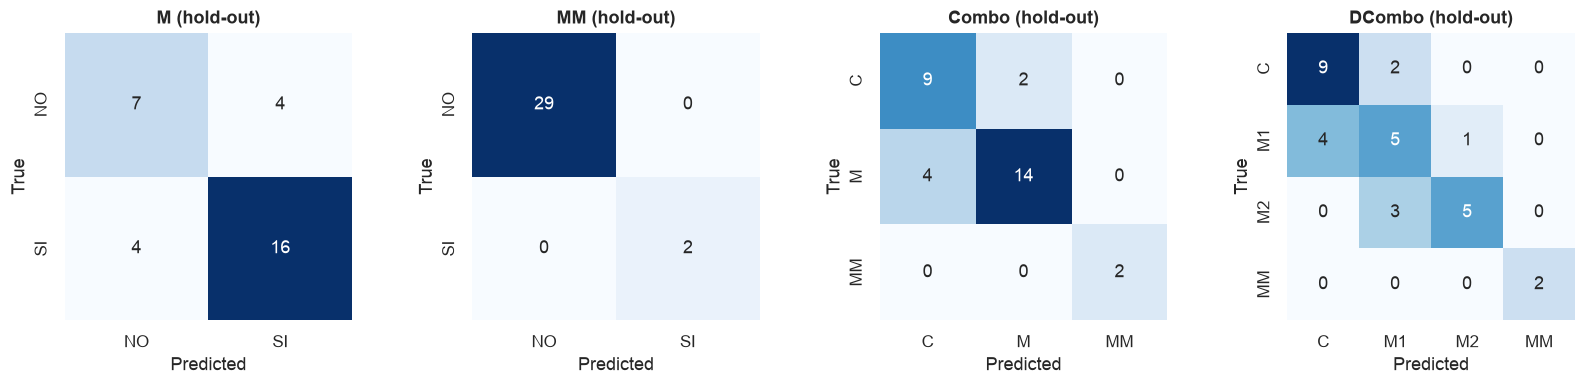

In [24]:
# Confusion matrices on the hold-out set
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, task in zip(axes, TASKS):
    cm = confusion_matrix(y_hold[task], hold_preds[task], labels=ORDERS[task])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True, ax=ax,
                xticklabels=ORDERS[task], yticklabels=ORDERS[task])
    ax.set(title=f"{task} (hold-out)", xlabel="Predicted", ylabel="True")
plt.tight_layout()
plt.show()

* **`MM` (1.000):** both severely myopic students are found, with no false alarm.
* **`Combo` (0.806) and `DCombo` (0.677)** are slightly above their cross-validation estimates
  (0.764 and 0.631), and **`M` (0.742)** is about 2 students below its estimate (0.804). With 31
  students each error costs 3 points, so these differences are within the noise of such a small
  set. They also remind us that the real test score can easily move by ±10 points.
* **MSE on the hold-out** is close to its cross-validation value (`M` 0.156 vs. 0.147, `Combo` 0.107
  vs. 0.111, `DCombo` 0.119 vs. 0.120). For `MM` it is practically 0: the random forest gave the two
  severe students a probability close to 1 and everyone else a probability close to 0.
* **The errors are always between C and M1, or between M1 and M2.** The `MM` group is always
  right, thanks to the variables built in Section 5.
* The most common errors are calling a myopic student "C" (4 of the 10 M1 students) and placing
  M2 students in M1 (3 of 8). Their eyes are in the zone where the groups overlap.

### 7.1 Overfitting and underfitting

The classic picture of prediction error against model complexity:
* **Model:** logistic regression trained directly on each task (the chosen model of `M` and
  `DCombo`, and tied best in `MM`).
* **Complexity:** the penalty C, the same for Lasso and the model. A small C (strong penalty)
  gives a simple model with few variables; a large C (weak penalty) gives a complex one.
* **Error:** MSE of the predicted probabilities, on the training students (93), in
  cross-validation (25 rounds) and on the hold-out (31).
* **Underfitting** (high bias): all errors are high. **Overfitting** (high variance): the
  training error keeps falling while the validation and hold-out errors rise again.

This is only a check: nothing is chosen from the hold-out. The dotted line marks the C chosen
by cross-validation (0.1).

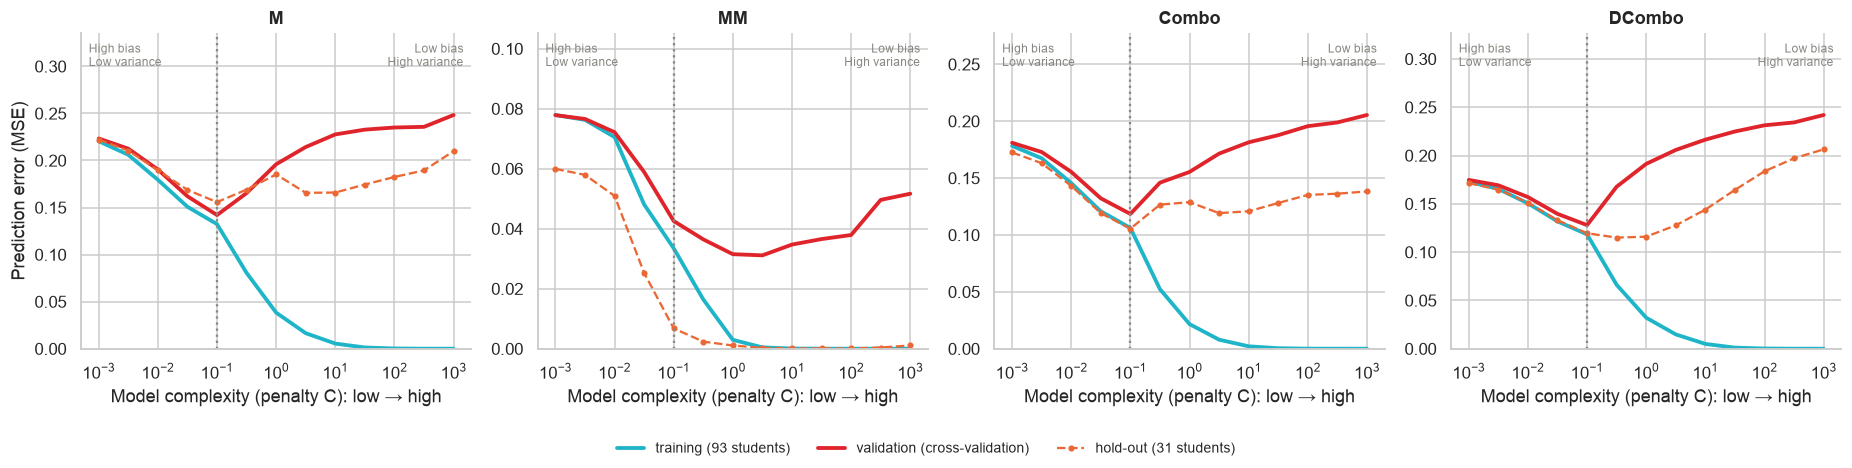

In [25]:
# Prediction error (MSE) of logistic regression for a range of penalties C, from simple to complex
C_VALUES = np.logspace(-3, 3, 13)
all_rows = np.arange(len(X_train))


# Fit with one penalty C; return the error on the students it was trained on and on new students
def train_and_test_mse(task, c, train_idx, X_new, y_new):
    model = pipeline(LogisticRegression(C=c, max_iter=5000)).set_params(lasso__C=c)
    model.fit(X_train.iloc[train_idx], y_train[task].iloc[train_idx])
    return (mse(y_train[task].iloc[train_idx], model.predict_proba(X_train.iloc[train_idx]), model.classes_),
            mse(y_new, model.predict_proba(X_new), model.classes_))


# Training and hold-out error: fit on the 93 training students. Validation error: the 25 rounds
def run_job(task, c, k):
    if k is None:
        return train_and_test_mse(task, c, all_rows, X_hold, y_hold[task])
    tr, te = cv_splits[k]
    return train_and_test_mse(task, c, tr, X_train.iloc[te], y_train[task].iloc[te])


jobs = ([(task, c, None) for task in TASKS for c in C_VALUES]
        + [(task, c, k) for task in TASKS for c in C_VALUES for k in range(len(cv_splits))])
with parallel_config(backend="loky", inner_max_num_threads=1):
    results = Parallel(n_jobs=-1)(delayed(run_job)(*job) for job in jobs)
errors = pd.DataFrame([{"task": t, "C": c, "round": k, "train": a, "test": b}
                       for (t, c, k), (a, b) in zip(jobs, results)])
hold = errors[errors["round"].isna()].set_index(["task", "C"])
validation = errors[errors["round"].notna()].groupby(["task", "C"])["test"].mean()

# One panel per task: training, validation and hold-out error against complexity
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
for ax, task in zip(axes, TASKS):
    ax.plot(C_VALUES, hold.loc[task]["train"], color="#1fb5c9", lw=2.5, label="training (93 students)")
    ax.plot(C_VALUES, validation.loc[task], color="#e0242b", lw=2.5, label="validation (cross-validation)")
    ax.plot(C_VALUES, hold.loc[task]["test"], color=ORANGE, lw=1.5, ls="--", marker="o", ms=3,
            label="hold-out (31 students)")
    ax.axvline(0.1, color=GREY, ls=":")
    top = max(hold.loc[task][["train", "test"]].max().max(), validation.loc[task].max())
    ax.set_ylim(0, top * 1.35)
    ax.text(0.02, 0.97, "High bias\nLow variance", transform=ax.transAxes, va="top", fontsize=8, color=GREY)
    ax.text(0.98, 0.97, "Low bias\nHigh variance", transform=ax.transAxes, va="top", ha="right",
            fontsize=8, color=GREY)
    ax.set(xscale="log", title=task, xlabel="Model complexity (penalty C): low → high")
axes[0].set_ylabel("Prediction error (MSE)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

* **The chosen complexity is right:** in `M`, `Combo` and `DCombo` the validation error is lowest at the C chosen by cross-validation (0.1); simpler models underfit (high bias) and more complex ones overfit (high variance).
* **The models generalise:** at that C the training and validation errors are close, so the models do not memorise the training students.
* **More complexity would not help:** the remaining error comes from groups that overlap in the data, so improving it would need more information, not more complex models.

## 8. Predictions for the test set

For the final predictions the chosen models are trained again on **all 124 labelled students**
(training part + hold-out; the 8 with wrong labels were removed): more data gives
a better model, and the hold-out has already done its job. Only now is `X_test.csv` read. It passes through the fitted pipelines, which learn
nothing from it, and the predictions are saved in `Y_test_predictions.txt` with the same
format as `Y_train.csv`.

In [26]:
# Read the test students and predict them with the chosen models, retrained on all 124 labelled students
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
_, test_preds, test_probas = fit_and_predict(X_all, y_all, X_test)
predictions = pd.DataFrame(test_preds)[TASKS]

# Save the predictions with the same format as Y_train.csv and count how many students get each label
predictions[TASKS].to_csv("Y_test_predictions.txt", index=False)
print(f"Saved Y_test_predictions.txt: {predictions.shape[0]} students x {predictions.shape[1]} labels")
display(predictions.apply(lambda s: s.value_counts()).fillna(0).astype(int).T)

# The four labels come from different models, so a few students may get combinations that do not fit
consistent = np.logical_and.reduce([predictions[task] == predictions["DCombo"].map(mapping)
                                    for task, mapping in DERIVED.items()])
print(f"Students whose four predicted labels fit together: {consistent.sum()} of {len(predictions)}")

# First rows of the predictions
predictions.head()

Saved Y_test_predictions.txt: 24 students x 4 labels


,C,M,M1,M2,MM,NO,SI
M,0,0,0,0,0,11,13
MM,0,0,0,0,0,19,5
Combo,9,10,0,0,5,0,0
DCombo,9,0,7,3,5,0,0


Students whose four predicted labels fit together: 22 of 24


,M,MM,Combo,DCombo
0,SI,SI,MM,MM
1,NO,NO,C,C
2,SI,SI,MM,MM
3,NO,NO,C,C
4,NO,NO,M,M1


**Estimated MSE.** The test students have no labels, so their real MSE cannot be computed. We
estimate it from each model's own probabilities: if a class has probability p and that
probability is right, the expected squared error for that class is p(1 - p). The hold-out shows
how close this estimate is to the real MSE.

In [27]:
# Expected MSE if the probabilities are right: average of p(1 - p) over students and classes
def estimated_mse(proba):
    return np.mean(proba * (1 - proba))


# Estimated MSE on the test set, next to the estimated and the real MSE on the hold-out
pd.DataFrame({"estimated MSE, test": {task: estimated_mse(test_probas[task]) for task in TASKS},
              "estimated MSE, hold-out": {task: estimated_mse(hold_probas[task]) for task in TASKS},
              "real MSE, hold-out": pd.DataFrame(hold_rows).set_index("task")["MSE"]}
             ).style.format(precision=3)

,"estimated MSE, test","estimated MSE, hold-out","real MSE, hold-out"
M,0.115,0.179,0.156
MM,0.025,0.004,0.000
Combo,0.080,0.143,0.107
DCombo,0.084,0.147,0.119


* **On the hold-out, the estimate was somewhat higher than the real MSE** (`M` 0.179 vs. 0.156,
  `Combo` 0.143 vs. 0.107, `DCombo` 0.147 vs. 0.119): the models were right more often than their
  own probabilities suggested, so the estimate is a cautious guess.
* **On the test set the estimates are lower** (`M` 0.115, `MM` 0.025, `Combo` 0.080, `DCombo` 0.084).
  The final models, trained on 124 students, give more confident probabilities for these 24
  students, but more confidence only lowers the real MSE if the models are also right.
* The cross-validation and hold-out MSE (about 0.11-0.16 for `M`, `Combo` and `DCombo`, below 0.05
  for `MM`) remain the most reliable expectation for the test set.

## 9. Conclusions

**What determines myopia in these data?**
* **Eye measurements:** above all eye length combined with curvature, and for severe myopia an eye
  of 26 mm or longer. Lasso keeps almost nothing else.
* **Family history** is related to myopia but adds little once the eye length is known.
* **Lifestyle and sun habits** (outdoor hours, study hours, screens, sun protection) show weak
  differences between groups and no predictive value here.
* **Wrong labels:** 8 students are `MM` in `Combo`/`DCombo` but NO in `MM`. One of the two labels is
  wrong and we cannot tell which, so we removed them before splitting the data instead of guessing.

**Final models** (accuracy):

| Task | Model | Cross-validation (93 students) | Hold-out (31 students) | Baseline on the hold-out |
|---|---|---|---|---|
| `M` | Logistic regression (threshold 0.60) | 0.804 | 0.742 | 0.645 |
| `MM` | Random forest (threshold 0.40) | 0.964 | 1.000 | 0.935 |
| `Combo` | Read from the `DCombo` model | 0.764 | 0.806 | 0.581 |
| `DCombo` | Logistic regression | 0.631 | 0.677 | 0.355 |

* With so few students, **simple models are as good as complex ones**: logistic regression is the
  best (or tied for best) in every task.
* **The chosen complexity is the right one** (Section 7.1). We use the error-against-complexity curves
  to check the choice made by cross-validation: the validation error is lowest around the chosen
  penalty, simpler models underfit and more complex ones overfit. There, the training and validation
  errors are close, so the remaining error comes from the data (the groups overlap), not from the
  model: improving it would need more information, not more complex models.
* **`Combo` is read from the `DCombo` model**, which is slightly more accurate than a dedicated
  model. `M` and `MM` keep their own models.
* The models were retrained on all 124 students to predict the test set (`Y_test_predictions.txt`).
  * 22 of the 24 test students get four labels that fit together.
  * The other 2 are borderline cases between C and M1: the `M` model says NO, the `DCombo` model
    says M1.

**Limitations**
* **Small data.** Accuracy varies by 3-11 points between cross-validation rounds, and the hold-out
  has only 31 students, 2 of them severely myopic.
* **The 26 mm cut-off** is only known approximately, so test students near it remain uncertain.
* **The removed students.** If the hidden test labels contain the same kind of error, our models,
  trained only on labels that fit together, cannot reproduce it.